# Job Market Analytics: Tasks 2, 3 & 4 (improved)
**Goal:** clean the scraped Jobicy data, explore it, and train a salary model that powers a
website: *seniority + experience + skills + preferred domain -> predicted annual salary (USD)*.

Input: `cleaned_from_pbix.csv` (the 1,021-row table from the Power BI model; same as
`cleaned_job_market_data.csv` produced by your original notebook).

In [1]:
import json, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
import os; os.makedirs("charts", exist_ok=True); os.makedirs("model", exist_ok=True)

df = pd.read_csv("cleaned_from_pbix.csv")
print("Shape:", df.shape)
display(df.head())


Shape: (1021, 61)


,Job_ID,Job_Title,Company,Location,Job_Level,Job_Industry,Employment_Type,Job_Description,Job_Excerpt,Publication_Date,...,Skill_Django,Skill_Flask,Skill_TensorFlow,Skill_PyTorch,Skill_Statistics,Skill_NLP,Skill_Count,Description_Length,Word_Count,Annual_Salary_USD
0,152475,Account Executive - EMEA Specialist,Samsara,UK,Director,Sales,Full-Time,Who we are Samsara (NYSE: IOT) is the pioneer ...,Who we are Samsara (NYSE: IOT) is the pioneer ...,2026-09-26 16:50:06.000000282,...,0,0,0,0,0,0,0,7763,1173,NaN
1,150381,Software Architect,Autodesk,"EMEA, UK",Senior,Software Engineering,Full-Time,Job Requisition ID # 26WD94957 Position Overvi...,Job Requisition ID #26WD94957Position Overview...,2026-09-26 16:45:21.999999905,...,0,0,0,0,0,0,3,9183,1257,NaN
2,150370,"Technical Account Specialist - Storm, Sewer, F...",Autodesk,UK,Any,Technical Support,Full-Time,Job Requisition ID # 26WD99973 Position Overvi...,Job Requisition ID #26WD99973Position Overview...,2026-09-26 16:45:20.000000064,...,0,0,0,0,0,0,1,4649,720,NaN
3,149313,"Technical Adoption Specialist, Civil 3D, Frenc...",Autodesk,"Poland, Spain",Senior,Customer Support & Success,Full-Time,Job Requisition ID # 26WD99616 Position overvi...,Job Requisition ID #26WD99616Position overview...,2026-09-26 16:45:16.999999989,...,0,0,0,0,0,0,0,3340,498,NaN
4,148712,"Renewals Representative, Account Based, Denmark",Autodesk,Denmark,Any,Sales,Full-Time,Job Requisition ID # 26WD98510 Position overvi...,Job Requisition ID #26WD98510Position overview...,2026-09-26 16:45:15.000000157,...,0,0,0,0,0,0,0,5706,771,NaN


## TASK 2 - Data cleaning (fixes to the salary pipeline)
Problems found in the original salary column:
* values like `1.5`, `194` (salary written in thousands) and `6,300` (50-1000 per *month* career-coach ranges)
* a range of `190,000 - 1,700,000` (clearly a data-entry error)
* 5 currencies had no exchange rate and were silently dropped
* the same listing posted many times (identical title/company/salary) which leaks between train and test

In [2]:
FX = {"USD":1.0,"EUR":1.08,"GBP":1.27,"CAD":0.73,"AUD":0.65,"NZD":0.60,"SGD":0.75,"INR":0.012,
      "CZK":0.043,"PLN":0.25,"HUF":0.0027,"CNY":0.14,"RON":0.22}
MULT = {"yearly":1,"monthly":12,"weekly":52,"daily":260,"hourly":2080}

s = df.copy()
s["period"] = s["Salary_Period"].astype(str).str.lower().str.strip()
lo, hi = s["Salary_Min"], s["Salary_Max"]
s["sal_lo"] = lo.fillna(hi); s["sal_hi"] = hi.fillna(lo)


thousands = (s.period == "yearly") & (s.sal_hi < 1000)
s.loc[thousands, ["sal_lo","sal_hi"]] *= 1000

s["sal_mid"] = (s.sal_lo + s.sal_hi) / 2
s["annual_local"] = s.sal_mid * s.period.map(MULT)
s["Annual_Salary_USD_clean"] = s.annual_local * s.Salary_Currency.map(FX)

has = s.Annual_Salary_USD_clean.notna()
print("Rows with a salary:", has.sum())


bad_range  = (s.sal_hi / s.sal_lo) > 3
bad_value  = ~s.Annual_Salary_USD_clean.between(20_000, 500_000)
s["salary_ok"] = has & ~bad_range & ~bad_value
print("Removed as unreliable:", (has & ~s.salary_ok).sum())


dedup_key = s.Job_Title.str.lower() + "|" + s.Company.str.lower() + "|" + s.Annual_Salary_USD_clean.round(0).astype(str)
s["is_dup"] = s.salary_ok & dedup_key.duplicated()
s["use_for_model"] = s.salary_ok & ~s.is_dup
print("Reliable, de-duplicated salary rows for ML:", s.use_for_model.sum())

Rows with a salary: 500
Removed as unreliable: 8
Reliable, de-duplicated salary rows for ML: 492


In [3]:

LEVEL_MAP = {"Entry-Level, Junior":"Entry", "Midweight":"Mid", "Senior":"Senior", "Director":"Lead/Director", "Any":"Unspecified"}
s["Seniority"] = s.Job_Level.map(LEVEL_MAP).fillna("Unspecified")


DOMAIN_MAP = {"Marketing & Sales":"Sales & Marketing","Sales":"Sales & Marketing","Business Development":"Sales & Marketing","SEO":"Sales & Marketing",
              "Customer Support & Success":"Customer Support","Technical Support":"Customer Support",
              "QA & Testing":"Software Engineering"}
s["Domain"] = s.Job_Industry.replace(DOMAIN_MAP)
counts = s.loc[s.use_for_model,"Domain"].value_counts()
rare = counts[counts < 12].index
s["Domain"] = s.Domain.where(~s.Domain.isin(rare), "Other")
print(s.loc[s.use_for_model,"Domain"].value_counts())


s["exp_missing"] = s.Experience_Years_Extracted.isna().astype(int)
s["Experience_Years"] = s.Experience_Years_Extracted.clip(upper=20)
s["Experience_Years"] = s.Experience_Years.fillna(s.groupby("Seniority")["Experience_Years"].transform("median"))
s["Experience_Years"] = s.Experience_Years.fillna(s.Experience_Years.median())

skill_cols = [c for c in s.columns if c.startswith("Skill_") and c != "Skill_Count"]
s.to_csv("cleaned_job_market_data_v2.csv", index=False)
print("Saved cleaned_job_market_data_v2.csv", s.shape)

Domain
Software Engineering            128
Sales & Marketing               107
Data Science & Analytics         63
Product & Operations             46
Other                            32
Cybersecurity                    28
Customer Support                 28
Finance & Accounting             22
DevOps & Infrastructure          21
Project & Program Management     17
Name: count, dtype: int64


Saved cleaned_job_market_data_v2.csv (1021, 74)


## TASK 3 - Exploratory Data Analysis

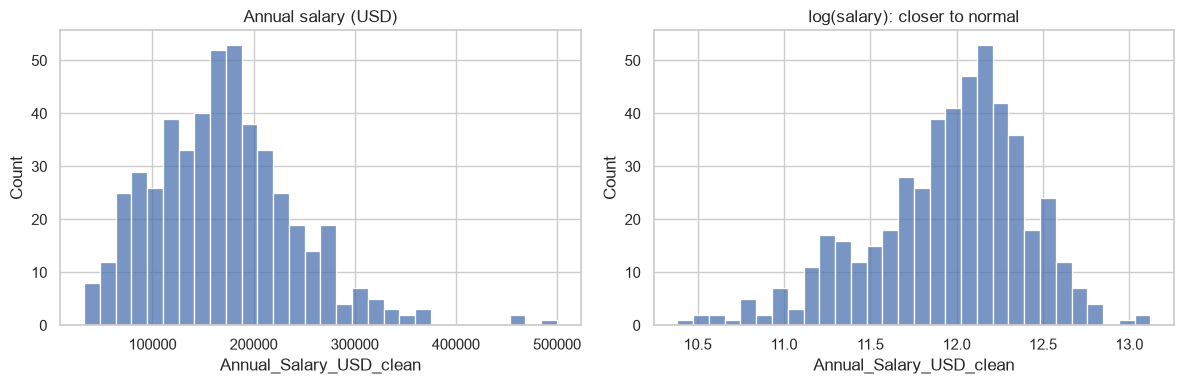

In [4]:
m = s[s.use_for_model].copy()
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(m.Annual_Salary_USD_clean, bins=30, ax=ax[0]); ax[0].set_title("Annual salary (USD)")
sns.histplot(np.log1p(m.Annual_Salary_USD_clean), bins=30, ax=ax[1]); ax[1].set_title("log(salary): closer to normal")
plt.tight_layout(); plt.savefig("charts/salary_dist.png", dpi=130); plt.show()

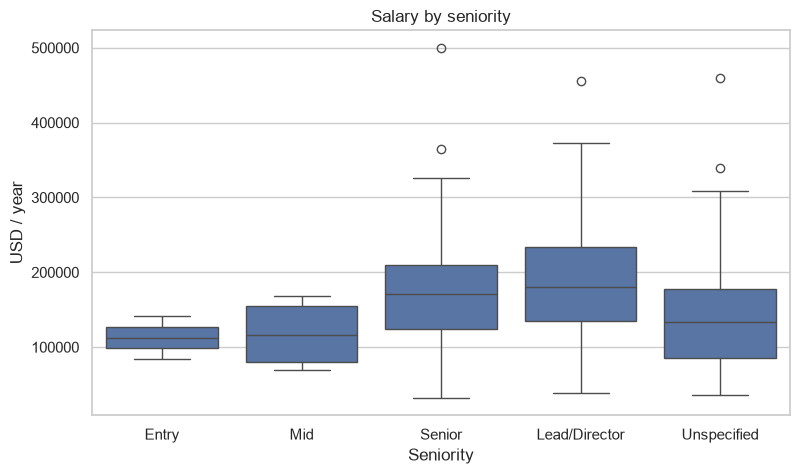

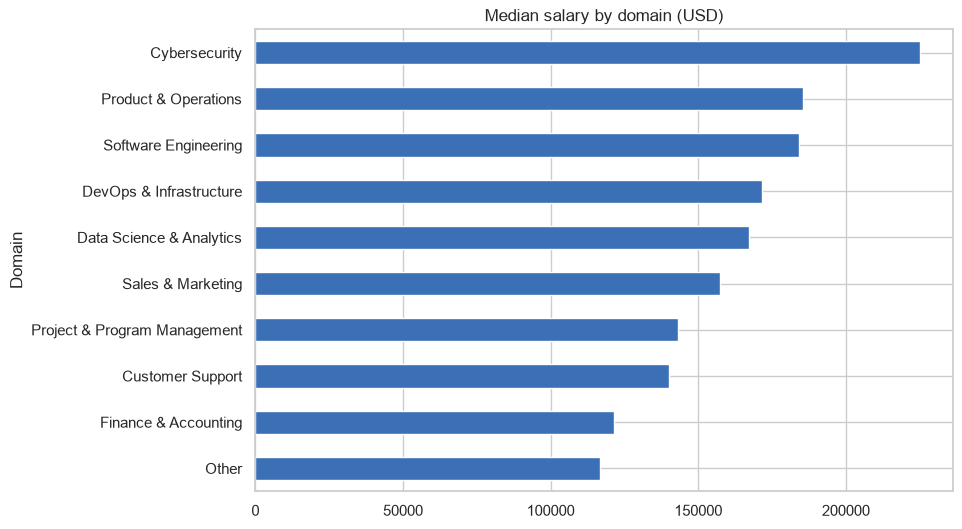

,median,count
Domain,,
Other,116617.5,32
Finance & Accounting,121300.0,22
Customer Support,140250.0,28
Project & Program Management,143100.0,17
Sales & Marketing,157500.0,107
Data Science & Analytics,167272.2,63
DevOps & Infrastructure,171450.0,21
Software Engineering,184250.0,128
Product & Operations,185500.0,46


In [5]:
order = ["Entry","Mid","Senior","Lead/Director","Unspecified"]
plt.figure(figsize=(9,5))
sns.boxplot(data=m, x="Seniority", y="Annual_Salary_USD_clean", order=order)
plt.title("Salary by seniority"); plt.ylabel("USD / year"); plt.savefig("charts/salary_seniority.png", dpi=130); plt.show()

dom = m.groupby("Domain").Annual_Salary_USD_clean.agg(["median","count"]).sort_values("median")
plt.figure(figsize=(9,6)); dom["median"].plot(kind="barh", color="#3b6fb6")
plt.title("Median salary by domain (USD)"); plt.savefig("charts/salary_domain.png", dpi=130); plt.show()
display(dom)

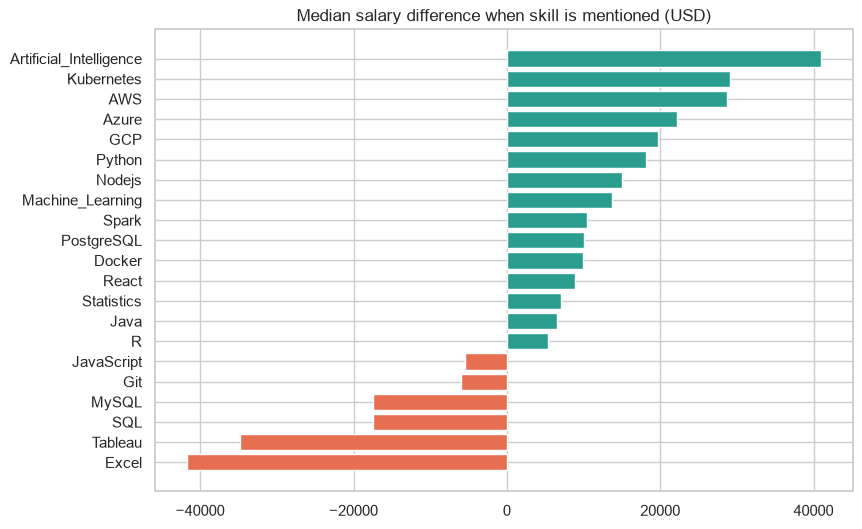

In [6]:

rows=[]
for c in skill_cols:
    w = m[m[c]==1].Annual_Salary_USD_clean
    if len(w) >= 15:
        rows.append((c.replace("Skill_",""), len(w), w.median(), m[m[c]==0].Annual_Salary_USD_clean.median()))
sk = pd.DataFrame(rows, columns=["Skill","Postings","Median_with","Median_without"])
sk["Premium"] = sk.Median_with - sk.Median_without
sk = sk.sort_values("Premium")
plt.figure(figsize=(9,6)); plt.barh(sk.Skill, sk.Premium, color=np.where(sk.Premium>0,"#2a9d8f","#e76f51"))
plt.title("Median salary difference when skill is mentioned (USD)"); plt.savefig("charts/skill_premium.png", dpi=130); plt.show()
sk.to_csv("skill_premium.csv", index=False)

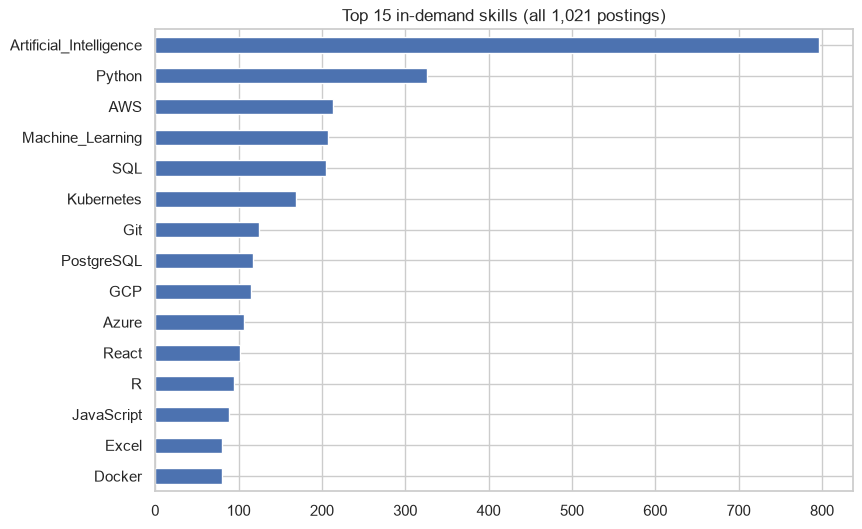

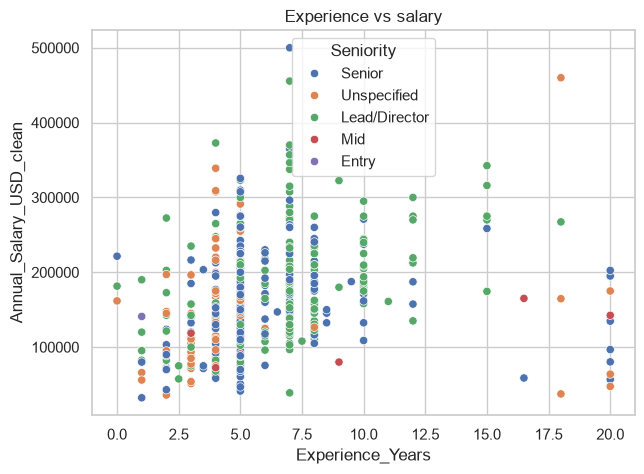

Spearman corr (experience, salary): 0.329
Spearman corr (skill count, salary): 0.14


In [7]:
top = s[skill_cols].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(9,6)); top.sort_values().rename(lambda x:x.replace("Skill_","")).plot(kind="barh")
plt.title("Top 15 in-demand skills (all 1,021 postings)"); plt.savefig("charts/top_skills.png", dpi=130); plt.show()

plt.figure(figsize=(7,5)); sns.scatterplot(data=m, x="Experience_Years", y="Annual_Salary_USD_clean", hue="Seniority")
plt.title("Experience vs salary"); plt.savefig("charts/exp_salary.png", dpi=130); plt.show()
print("Spearman corr (experience, salary):", m[["Experience_Years","Annual_Salary_USD_clean"]].corr("spearman").iloc[0,1].round(3))
print("Spearman corr (skill count, salary):", m[["Skill_Count","Annual_Salary_USD_clean"]].corr("spearman").iloc[0,1].round(3))

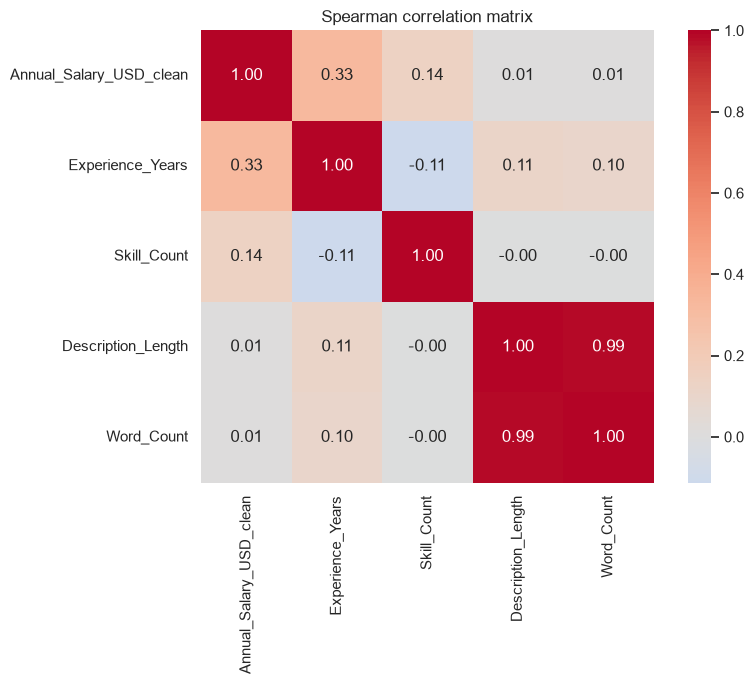

,Annual_Salary_USD_clean,Experience_Years,Skill_Count,Description_Length,Word_Count
Annual_Salary_USD_clean,1.000,0.329,0.140,0.008,0.008
Experience_Years,0.329,1.000,-0.113,0.114,0.104
Skill_Count,0.140,-0.113,1.000,-0.004,-0.001
Description_Length,0.008,0.114,-0.004,1.000,0.988
Word_Count,0.008,0.104,-0.001,0.988,1.000


,Metric,Value
0,Rows used for modeling,492.000
1,Median salary (USD),167136.100
2,Mean salary (USD),170243.276
3,Minimum salary (USD),32307.000
4,Maximum salary (USD),500000.000
5,Median experience (years),5.000
6,Median skill count,2.000
7,Experience-salary correlation,0.329
8,Skill-count-salary correlation,0.140


In [8]:
numeric_cols = [
    c for c in [
        "Annual_Salary_USD_clean",
        "Experience_Years",
        "Skill_Count",
        "Description_Length",
        "Word_Count",
    ]
    if c in m.columns
]

correlation = m[numeric_cols].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig("charts/correlation_heatmap.png", dpi=130)
plt.show()
display(correlation.round(3))

salary_metrics = pd.DataFrame({
    "Metric": [
        "Rows used for modeling",
        "Median salary (USD)",
        "Mean salary (USD)",
        "Minimum salary (USD)",
        "Maximum salary (USD)",
        "Median experience (years)",
        "Median skill count",
        "Experience-salary correlation",
        "Skill-count-salary correlation",
    ],
    "Value": [
        len(m),
        m["Annual_Salary_USD_clean"].median(),
        m["Annual_Salary_USD_clean"].mean(),
        m["Annual_Salary_USD_clean"].min(),
        m["Annual_Salary_USD_clean"].max(),
        m["Experience_Years"].median(),
        m["Skill_Count"].median(),
        correlation.loc["Experience_Years", "Annual_Salary_USD_clean"],
        correlation.loc["Skill_Count", "Annual_Salary_USD_clean"],
    ],
})
salary_metrics["Value"] = salary_metrics["Value"].round(3)
display(salary_metrics)


## TASK 4 - Machine learning
* Target = `log1p(annual salary USD)` (salary is right skewed); predictions converted back to USD.
* Features: seniority, years of experience, **individual skills** (not only a count), skill count, domain.
* Models compared with **repeated 5-fold CV** (the notebook originally trusted one 99-row test split).

In [9]:
from sklearn.model_selection import RepeatedKFold, cross_validate, train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error



model_skills = [c for c in skill_cols if m[c].sum() >= 10 and c != "Skill_R"]
m["Skill_Count"] = m[model_skills].sum(axis=1)
cat = ["Seniority","Domain"]
num = ["Experience_Years","Skill_Count"] + model_skills
X = m[cat+num]; y = m.Annual_Salary_USD_clean

def make(est):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                             ("num", StandardScaler(), num)])
    return TransformedTargetRegressor(Pipeline([("pre",pre),("est",est)]), func=np.log1p, inverse_func=np.expm1)

models = {
  "Baseline (median)": DummyRegressor(strategy="median"),
  "Ridge": RidgeCV(alphas=np.logspace(-1,3,20)),
  "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=4, max_features=0.5, random_state=42, n_jobs=-1),
  "Gradient Boosting": GradientBoostingRegressor(n_estimators=250, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=42),
}
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {"r2":"r2","rmse":"neg_root_mean_squared_error","mae":"neg_mean_absolute_error"}
res=[]
for name, est in models.items():
    r = cross_validate(make(est), X, y, cv=cv, scoring=scoring, n_jobs=-1)
    res.append({"Model":name,"CV_R2":r["test_r2"].mean(),"R2_std":r["test_r2"].std(),
                "CV_RMSE":-r["test_rmse"].mean(),"CV_MAE":-r["test_mae"].mean()})
cmp_ = pd.DataFrame(res).round(3); display(cmp_)

,Model,CV_R2,R2_std,CV_RMSE,CV_MAE
0,Baseline (median),-0.011,0.016,70802.934,55120.664
1,Ridge,0.095,0.117,66792.954,50890.857
2,Random Forest,0.198,0.072,63104.331,47528.264
3,Gradient Boosting,0.251,0.079,60906.531,46141.988


In [10]:

best_name = cmp_.sort_values("CV_RMSE").iloc[0].Model
print("Best by CV RMSE:", best_name)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

grid = {"regressor__est__n_estimators":[200,400],"regressor__est__max_depth":[2,3,4],
        "regressor__est__learning_rate":[0.02,0.05],"regressor__est__min_samples_leaf":[3,6]}
if best_name == "Gradient Boosting":
    gs = GridSearchCV(make(GradientBoostingRegressor(subsample=0.8, random_state=42)), grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
elif best_name == "Random Forest":
    grid = {"regressor__est__max_depth":[4,6,None],"regressor__est__min_samples_leaf":[3,5,8],"regressor__est__max_features":[0.3,0.5,0.8]}
    gs = GridSearchCV(make(RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)), grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=1)
else:
    gs = GridSearchCV(make(RidgeCV(alphas=np.logspace(-1,3,20))), {}, cv=5)
gs.fit(X_tr, y_tr)
pred = gs.predict(X_te)
test = {"R2":r2_score(y_te,pred),"RMSE":mean_squared_error(y_te,pred)**.5,"MAE":mean_absolute_error(y_te,pred)}
print("Best params:", gs.best_params_); print({k:round(v,3) for k,v in test.items()})

Best by CV RMSE: Gradient Boosting


Best params: {'regressor__est__learning_rate': 0.02, 'regressor__est__max_depth': 4, 'regressor__est__min_samples_leaf': 6, 'regressor__est__n_estimators': 400}
{'R2': 0.356, 'RMSE': 58584.655, 'MAE': 44970.596}


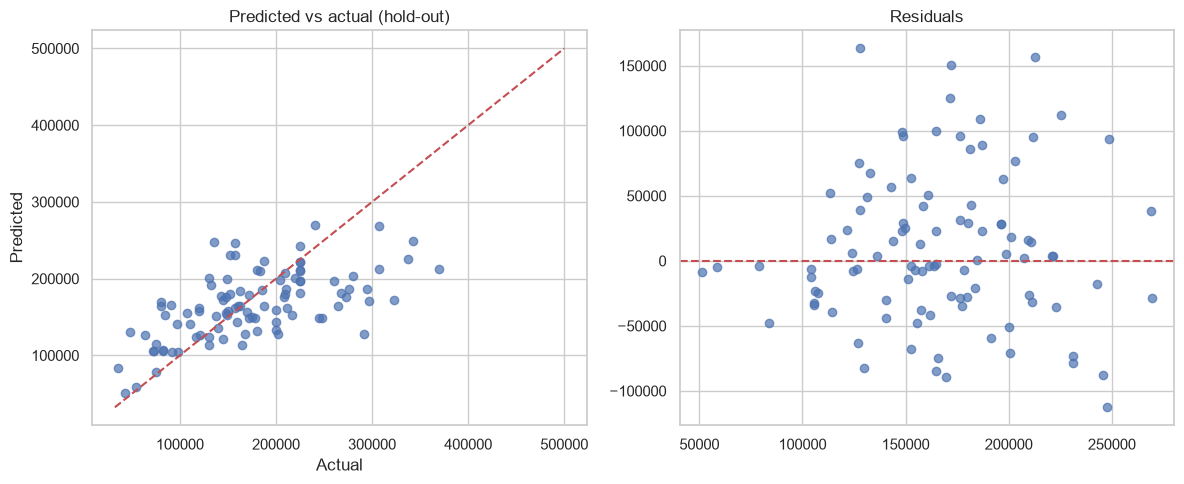

In [11]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].scatter(y_te, pred, alpha=.7); lim=[y.min(), y.max()]; ax[0].plot(lim,lim,"r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Predicted vs actual (hold-out)")
ax[1].scatter(pred, y_te-pred, alpha=.7); ax[1].axhline(0,color="r",ls="--"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.savefig("charts/pred_vs_actual.png", dpi=130); plt.show()

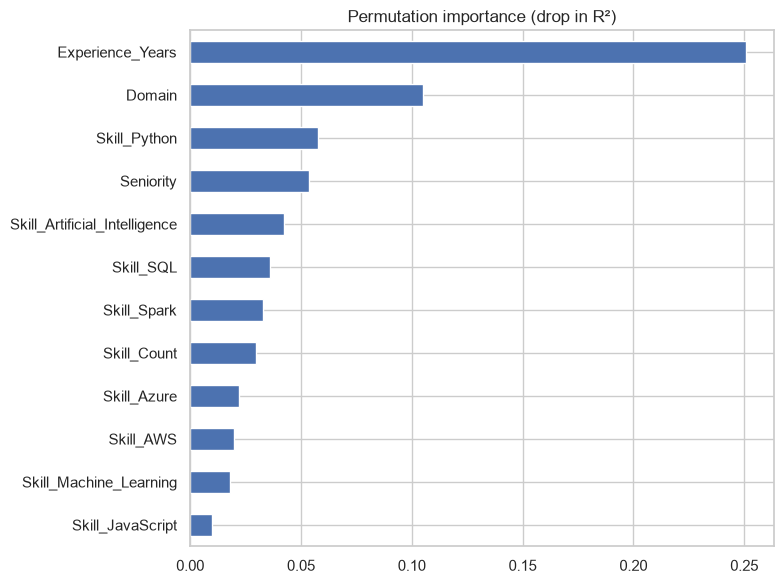

Experience_Years                 0.250888
Domain                           0.104889
Skill_Python                     0.057752
Seniority                        0.053712
Skill_Artificial_Intelligence    0.042120
Skill_SQL                        0.036192
Skill_Spark                      0.032836
Skill_Count                      0.029838
Skill_Azure                      0.022119
Skill_AWS                        0.019716
Skill_Machine_Learning           0.018168
Skill_JavaScript                 0.009915
dtype: float64

In [12]:

from sklearn.inspection import permutation_importance
pi = permutation_importance(gs.best_estimator_, X_te, y_te, n_repeats=30, random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6)); imp.head(12).sort_values().plot(kind="barh"); plt.title("Permutation importance (drop in R²)")
plt.tight_layout(); plt.savefig("charts/perm_importance.png", dpi=130); plt.show()
display(imp.head(12))

In [13]:

final = gs.best_estimator_.fit(X, y)
import joblib
joblib.dump(final, "model/salary_model.joblib")


from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final, X, y, cv=5)
ratio = np.log(y/oof); q10,q90 = np.quantile(ratio,[.10,.90])

meta = {
  "best_model": best_name,
  "cv_comparison": cmp_.to_dict("records"),
  "holdout": {k:float(v) for k,v in test.items()},
  "training_rows": int(len(X)),
  "interval_log_q10": float(q10), "interval_log_q90": float(q90),
  "levels": ["Entry","Mid","Senior","Lead/Director"],
  "domains": sorted(m.Domain.unique().tolist()),
  "skills": [c.replace("Skill_","") for c in model_skills],
  "skill_cols": model_skills,
  "median_exp_by_level": m.groupby("Seniority").Experience_Years.median().round(1).to_dict(),
}
json.dump(meta, open("model/meta.json","w"), indent=2)
print(json.dumps({k:meta[k] for k in ["best_model","holdout","training_rows"]}, indent=2))


pbi = m[["Job_ID","Job_Title","Company","Seniority","Domain","Experience_Years","Skill_Count","Annual_Salary_USD_clean"]].copy()
pbi["Predicted_Salary_USD"] = oof.round(0); pbi["Error_USD"] = (pbi.Predicted_Salary_USD - pbi.Annual_Salary_USD_clean).round(0)
pbi["Abs_Pct_Error"] = (pbi.Error_USD.abs()/pbi.Annual_Salary_USD_clean).round(3)
pbi.to_csv("powerbi_model_predictions.csv", index=False)
cmp_.to_csv("powerbi_model_comparison.csv", index=False)
imp.rename("Importance").reset_index().rename(columns={"index":"Feature"}).to_csv("powerbi_feature_importance.csv", index=False)
print("Exports written.")

{
  "best_model": "Gradient Boosting",
  "holdout": {
    "R2": 0.3559639280118698,
    "RMSE": 58584.65480463996,
    "MAE": 44970.59649554156
  },
  "training_rows": 492
}
Exports written.
